In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
from matplotlib.ticker import FormatStrFormatter
from matplotlib.lines import Line2D

In [2]:
data_sumN = pd.read_table("NIPBL_data_1.txt")
data_sumN_fc = pd.read_table("NIPBL_data_FC_1.txt")
guides = ["0", "96", "206", "409", "848"]

In [3]:
palette=["#83aac3", "#3c627c", "#ea9648", "#c96d18", "#aed6ca", "#305f51"]

/local/55263823.1.igmm_long/ipykernel_1281375/542070555.py:18: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  g = sns.stripplot(data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette,
/local/55263823.1.igmm_long/ipykernel_1281375/542070555.py:21: UserWarning: The palette list has more values (6) than needed (2), which may not be intended.
  sns.pointplot(


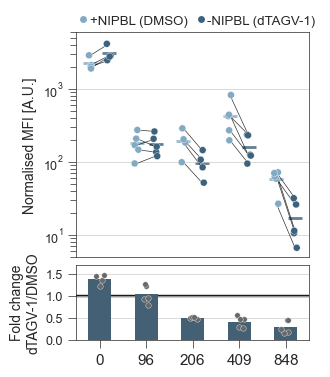

In [4]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
f, axs = plt.subplots(
    figsize=(3,4),
    nrows=2, 
    gridspec_kw={'height_ratios':[3,1], 'hspace':0.05}, 
    sharex=True,)

df=data_sumN

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG"]

df=df[df["guide"].isin(order)]
df2=data_sumN_fc

g = sns.stripplot(data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette,
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5, ax=axs[0],
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette,
    hue_order=hue_order, order=order, dodge=.4, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=axs[0])

for date in df["rep"].unique():
    dfpiv = df.loc[(df["rep"]==date),["treatment", "median_minus_bg","guide"]].pivot(columns="treatment", values="median_minus_bg", index="guide").reset_index()
    i = 0
    for guide in order:
        if guide in dfpiv["guide"].unique():
            axs[0].plot([i-0.2, i+0.2], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'black', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set(yscale="log", title="", ylim=[5, 6000])

axs[0].grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[0], markersize=6, label="+NIPBL (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[1], markersize=6, label="-NIPBL (dTAGV-1)")
]

axs[0].legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

axs[0].tick_params(
    axis='x',          
    which='both',      
    bottom=False,      
    top=False,        
    labelbottom=False)

h = sns.barplot(data=df2, y="FC", x="guide",
                  order=order, dodge=True, edgecolor="white", 
                  linewidth=0, alpha=1, ax=axs[1], width=0.5, 
                  color=palette[1], legend=False, errorbar=None)
sns.stripplot(data=df2, y="FC", x="guide", 
                  order=order, color="dimgrey",
                  dodge=0.5, jitter=0.1, edgecolor="white",  size=4, 
                  linewidth=0.25, alpha=1, zorder=5, ax=axs[1], legend=False)
h.set(title='', ylim=[0, 1.7], xlabel="")
plt.yticks([0, 0.5,1,1.5])
axs[1].axhline(1, color="k", zorder=0, linewidth=1.75)
axs[1].grid(True, axis="y", zorder=-1, linewidth=0.5)
axs[0].set_ylabel("Normalised MFI [A.U.]", fontsize=10)
axs[1].set_ylabel("Fold change\ndTAGV-1/DMSO", fontsize=10)
axs[0].tick_params(axis='y', labelsize=9)
axs[1].tick_params(axis='y', labelsize=9)

In [5]:
df = data_sumN
pval = pd.DataFrame()
for guide in guides:
    x = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "median_minus_bg"].tolist()
    y = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "median_minus_bg"].tolist()
    wc = ttest_rel(x, y, alternative="two-sided") 
    pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x)})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Guide"] + "_dTAGNIPBL-dTAG/DMSO"
pval["test"] = "ttest_rel"
pval.drop(columns="Guide").sort_values("padj")

,pval,N,padj,sig,log10_p,Condition,test
0,0.004104,5,0.020520,True,1.687831,848_dTAGNIPBL-dTAG/DMSO,ttest_rel
0,0.015389,4,0.026630,True,1.574629,0_dTAGNIPBL-dTAG/DMSO,ttest_rel
0,0.015978,4,0.026630,True,1.574629,206_dTAGNIPBL-dTAG/DMSO,ttest_rel
0,0.037916,5,0.047396,True,1.324262,409_dTAGNIPBL-dTAG/DMSO,ttest_rel
0,0.930279,5,0.930279,False,0.031387,96_dTAGNIPBL-dTAG/DMSO,ttest_rel


In [6]:
data_sumW = pd.read_table("WAPL_data_1.txt")
data_sumW_fc = pd.read_table("WAPL_data_FC_1.txt")

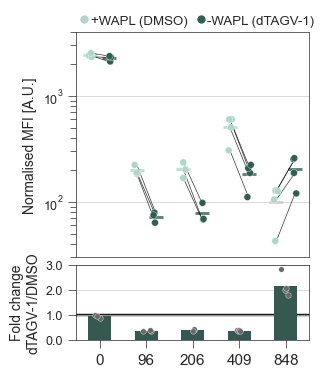

In [7]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1,1), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
f, axs = plt.subplots(
    figsize=(3,4),
    nrows=2, 
    gridspec_kw={'height_ratios':[3,1], 'hspace':0.05}, 
    sharex=True,)

df=data_sumW

order = [x for x in guides if x in df["guide"].unique()]
hue_order = ["DMSO", "dTAG"]

df=df[df["guide"].isin(order)]
df2=data_sumW_fc

g = sns.stripplot(data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette[4:],
                  hue_order=hue_order, order=order, dodge=True, jitter=0.1, edgecolor="white",  size=5, ax=axs[0],
                  linewidth=0.25, alpha=1, zorder=10)
sns.pointplot(
    data=df, y="median_minus_bg", x="guide", hue="treatment", palette=palette[4:],
    hue_order=hue_order, order=order, dodge=.4, linestyle="none", errorbar=None,
    marker="_", markersize=10,  zorder=-11, legend=False,  alpha=0.8, ax=axs[0])

for date in df["rep"].unique():
    dfpiv = df.loc[(df["rep"]==date),["treatment", "median_minus_bg","guide"]].pivot(columns="treatment", values="median_minus_bg", index="guide").reset_index()
    i = 0
    for guide in order:
        if guide in dfpiv["guide"].unique():
            axs[0].plot([i-0.2, i+0.2], np.array(dfpiv.loc[dfpiv["guide"]==guide, hue_order])[0],
                     color = 'black', linewidth = 0.5, linestyle = '-', zorder = 2, alpha=0.8)
        i += 1

g.set(yscale="log", title="", ylim=[30, 4000])

axs[0].grid(axis="y", zorder=-10, linewidth=0.5) 

handles = [
    Line2D([0], [0], marker='o', color='white', 
           markerfacecolor=palette[4], markersize=7, label="+WAPL (DMSO)"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor=palette[5], markersize=7, label="-WAPL (dTAGV-1)")
]

axs[0].legend(
    handles=handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    handletextpad=-0.5,
    columnspacing=0,
    fontsize=9.5
)

axs[0].tick_params(
    axis='x',          
    which='both',      
    bottom=False,      
    top=False,        
    labelbottom=False)

h = sns.barplot(data=df2, y="FC", x="guide",
                  order=order, dodge=True, edgecolor="white", 
                  linewidth=0, alpha=1, ax=axs[1], width=0.5, 
                  color=palette[5], legend=False, errorbar=None)
sns.stripplot(data=df2, y="FC", x="guide", 
                  order=order, color="dimgrey",
                  dodge=0.5, jitter=0.1, edgecolor="white",  size=4, 
                  linewidth=0.25, alpha=1, zorder=5, ax=axs[1], legend=False)
h.set(title='', ylim=[0, 1.7], xlabel="")
plt.yticks([0,1,2,3])
axs[1].axhline(1, color="k", zorder=0, linewidth=1.75)
axs[1].grid(True, axis="y", zorder=-1, linewidth=0.5)
axs[0].set_ylabel("Normalised MFI [A.U.]", fontsize=10)
axs[1].set_ylabel("Fold change\ndTAGV-1/DMSO", fontsize=10)
axs[0].tick_params(axis='y', labelsize=9)
axs[1].tick_params(axis='y', labelsize=9)
axs[1].yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

In [8]:
df = data_sumW
pval = pd.DataFrame()
for guide in guides:
    x = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="dTAG"), "median_minus_bg"].tolist()
    y = df.sort_values("rep").loc[(df["guide"] == guide) & (df["treatment"]=="DMSO"), "median_minus_bg"].tolist()
    wc = ttest_rel(x, y, alternative="two-sided") 
    pval = pd.concat([pval, pd.DataFrame({"Guide": [guide], "pval": [wc[1]], "N": len(x)})])
    
mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Guide"] + "_WAPLdTAG-dTAG/DMSO"
pval["test"] = "ttest_rel"
pval.drop(columns="Guide").sort_values("padj")

,pval,N,padj,sig,log10_p,Condition,test
0,0.005251,3,0.009497,True,2.022426,96_WAPLdTAG-dTAG/DMSO,ttest_rel
0,0.005698,4,0.009497,True,2.022426,409_WAPLdTAG-dTAG/DMSO,ttest_rel
0,0.005268,4,0.009497,True,2.022426,848_WAPLdTAG-dTAG/DMSO,ttest_rel
0,0.009452,3,0.011815,True,1.927584,206_WAPLdTAG-dTAG/DMSO,ttest_rel
0,0.173441,3,0.173441,False,0.760849,0_WAPLdTAG-dTAG/DMSO,ttest_rel
